# Homework 2: Impulse responses and forecast error variance decomposition

VAR(3) from Homework 1 in Bjørnland's ordering $Z_t=(i^*_t, y_t, \pi_t, i_t, \Delta e_t)'$ with a constant, a linear trend and dummies for 1992Q3, 1993Q1 and 1995Q4, 1983Q1–2004Q4. `VARSWE.xls` must be in this folder. For Question 3, `s_master.py` and the files with critical values must also be in this folder.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.stats import norm
from statsmodels.tsa.tsatools import vech

In [20]:
x = pd.read_excel('VARSWE.xls', header=5, index_col=0)
x.index = pd.to_datetime(x.index)

data = pd.DataFrame({
    'rfor':   x['rtwi'],
    'lgdp':   np.log(x['GDP']),
    'pi':     100 * x['Aldp'],
    'rdom':   x['r'],
    'dlrexc': 100 * np.log(x['RERinv']).diff(),
}).loc['1983':'2004']

names = ['rfor', 'lgdp', 'pi', 'rdom', 'dlrexc']    # ordering in Bjørnland, eq. (3)
y = data[names].to_numpy()
T, K = y.shape
p = 3

dum = x.loc['1983':'2004', ['du92Q3', 'du93Q1', 'du95Q4']].to_numpy()
det = np.hstack([np.ones((T, 1)), np.arange(1, T + 1).reshape(-1, 1), dum])   # constant, trend, dummies

# positions of variables and shocks
iy, ipi, ir, ie = 1, 2, 3, 4      # lgdp, pi, rdom, dlrexc
mp, er = 3, 4                     # monetary policy shock, exchange rate shock
h = 23                            # horizons 0,...,23 (quarters 1,...,24)

#### Functions

`var_ols` and `companion` are from Homework 1. `irf` computes $\Theta_i=\Phi_iS$ with $\Phi_i=J\mathbf{A}^iJ'$. `irf_mp` gives the responses to a monetary policy shock scaled to a one percentage point increase in the interest rate on impact, with GDP in percent and the real exchange rate in levels (cumulated $\Delta e$). `fevd` computes the forecast error variance decomposition.

In [12]:
def var_ols(y, p, det):
    T, K = y.shape
    Y = y[p:]
    X = np.hstack([det[p:]] + [y[p - i:T - i] for i in range(1, p + 1)])
    B = np.linalg.solve(X.T @ X, X.T @ Y)
    U = Y - X @ B
    Sigma = U.T @ U / (Y.shape[0] - X.shape[1])
    m = det.shape[1]
    Alags = [B[m + (i - 1) * K:m + i * K].T for i in range(1, p + 1)]
    return Alags, Sigma, U, B, X


def companion(Alags):
    K, p = Alags[0].shape[0], len(Alags)
    A = np.zeros((K * p, K * p))
    A[:K] = np.hstack(Alags)
    A[K:, :-K] = np.eye(K * (p - 1))
    return A


def irf(A, S, h):
    K = S.shape[0]
    J = np.hstack([np.eye(K), np.zeros((K, A.shape[0] - K))])
    Theta = np.zeros((h + 1, K, K))
    Ai = np.eye(A.shape[0])
    for i in range(h + 1):
        Theta[i] = J @ Ai @ J.T @ S
        Ai = Ai @ A
    return Theta


def irf_mp(A, S, h):
    Theta = irf(A, S, h)
    resp = Theta[:, :, mp] / Theta[0, ir, mp]
    resp[:, iy] = 100 * resp[:, iy]              # GDP in percent
    resp[:, ie] = np.cumsum(resp[:, ie])         # level of the real exchange rate
    return resp                                  # (h+1, K)


def fevd(Theta):
    contrib = np.cumsum(Theta**2, axis=0)
    return contrib / contrib.sum(axis=2, keepdims=True)    # [horizon, variable, shock]

## Question 1

$S_{45}=0$: $S=\mathrm{chol}(\Sigma_u)$. $S_{54}=0$: swap $i$ and $\Delta e$ with a permutation matrix $P$ and set $S=P'\,\mathrm{chol}(P\Sigma_uP')\,P$.

In [13]:
def chol_identify(Sigma, order):
    P = np.eye(Sigma.shape[0])[order]
    L = np.linalg.cholesky(P @ Sigma @ P.T)
    return P.T @ L @ P


Alags, Sigma, U, B, X = var_ols(y, p, det)
A = companion(Alags)
print('Effective sample:', U.shape[0])
print('Largest eigenvalue modulus:', np.abs(np.linalg.eigvals(A)).max().round(4))

S_45 = chol_identify(Sigma, [0, 1, 2, 3, 4])    # i before e: S45 = 0
S_54 = chol_identify(Sigma, [0, 1, 2, 4, 3])    # e before i: S54 = 0

shocks = ['e_i*', 'e_Y', 'e_CP', 'e_MP', 'e_ER']
print('\nS with S45 = 0'); print(pd.DataFrame(S_45, index=names, columns=shocks).round(3))
print('\nS with S54 = 0'); print(pd.DataFrame(S_54, index=names, columns=shocks).round(3))

Effective sample: 85
Largest eigenvalue modulus: 0.946

S with S45 = 0
         e_i*    e_Y   e_CP   e_MP   e_ER
rfor    0.361  0.000  0.000  0.000  0.000
lgdp   -0.001  0.007  0.000  0.000  0.000
pi      0.036 -0.063  0.751  0.000  0.000
rdom    0.213  0.042  0.178  0.702  0.000
dlrexc  0.036 -0.291 -0.195  0.042  1.888

S with S54 = 0
         e_i*    e_Y   e_CP   e_MP   e_ER
rfor    0.361  0.000  0.000  0.000  0.000
lgdp   -0.001  0.007  0.000  0.000  0.000
pi      0.036 -0.063  0.751  0.000  0.000
rdom    0.213  0.042  0.178  0.702  0.016
dlrexc  0.036 -0.291 -0.195  0.000  1.889


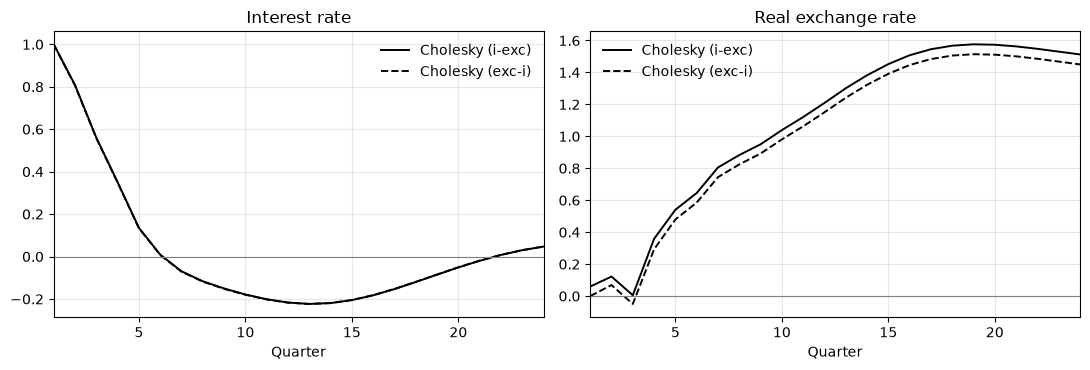

,i (i-exc),e (i-exc),i (exc-i),e (exc-i)
1,1.000,0.060,1.000,0.000
2,0.808,0.122,0.806,0.069
3,0.560,0.005,0.558,-0.049
4,0.350,0.359,0.348,0.293
5,0.136,0.541,0.134,0.480
8,-0.116,0.883,-0.118,0.824
12,-0.217,1.209,-0.217,1.150
16,-0.183,1.508,-0.182,1.446
20,-0.051,1.573,-0.051,1.511
24,0.047,1.513,0.047,1.450


In [14]:
irf_45 = irf_mp(A, S_45, h)
irf_54 = irf_mp(A, S_54, h)

hz = np.arange(1, h + 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for j, (v, t) in enumerate([(ir, 'Interest rate'), (ie, 'Real exchange rate')]):
    ax[j].plot(hz, irf_45[:, v], '-', color='black', lw=1.4, label='Cholesky (i-exc)')
    ax[j].plot(hz, irf_54[:, v], '--', color='black', lw=1.4, label='Cholesky (exc-i)')
    ax[j].axhline(0, color='grey', lw=0.8)
    ax[j].set_title(t); ax[j].set_xlabel('Quarter'); ax[j].set_xlim(1, h + 1)
    ax[j].grid(alpha=0.3); ax[j].legend(frameon=False)
plt.tight_layout()
plt.savefig('q1_irf_cholesky.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame({'i (i-exc)': irf_45[:, ir], 'e (i-exc)': irf_45[:, ie],
              'i (exc-i)': irf_54[:, ir], 'e (exc-i)': irf_54[:, ie]}, index=hz).loc[[1, 2, 3, 4, 5, 8, 12, 16, 20, 24]].round(3)

## Question 2

$\omega_{kj}(h)=\sum_{i=0}^{h-1}\Theta_{i,kj}^2/\sum_{i=0}^{h-1}\sum_{l}\Theta_{i,kl}^2$, using the responses to unit-variance shocks.

In [15]:
fevd_45 = fevd(irf(A, S_45, h))
fevd_54 = fevd(irf(A, S_54, h))

hor = [1, 4, 8, 12, 24]
tab2 = pd.DataFrame({
    'i: MP (S45=0)': fevd_45[:, ir, mp], 'i: MP (S54=0)': fevd_54[:, ir, mp],
    'i: ER (S45=0)': fevd_45[:, ir, er], 'i: ER (S54=0)': fevd_54[:, ir, er],
    'e: MP (S45=0)': fevd_45[:, ie, mp], 'e: MP (S54=0)': fevd_54[:, ie, mp],
    'e: ER (S45=0)': fevd_45[:, ie, er], 'e: ER (S54=0)': fevd_54[:, ie, er],
}, index=hz)
(100 * tab2.loc[hor]).round(1)

,i: MP (S45=0),i: MP (S54=0),i: ER (S45=0),i: ER (S54=0),e: MP (S45=0),e: MP (S54=0),e: ER (S45=0),e: ER (S54=0)
1,86.2,86.2,0.0,0.0,0.0,0.0,96.6,96.6
4,56.5,56.3,0.8,1.1,1.6,1.5,83.4,83.5
8,37.2,37.1,1.1,1.2,2.3,2.2,78.6,78.7
12,35.2,35.0,1.1,1.2,2.5,2.4,76.8,76.9
24,32.0,31.9,1.0,1.1,2.6,2.6,73.7,73.8


## Question 3

VEC model H1 from Homework 1 ($p=3$, $r=3$, unrestricted constant, no dummies), estimated with the course functions `jcitestexog` and `LSKnownBeta` as in exercise class 8. The VEC model is a VAR(3) in levels with $A_1=I_K+\Pi+\Gamma_1$, $A_2=\Gamma_2-\Gamma_1$ and $A_3=-\Gamma_2$.

In [16]:
import sys, types
try:
    import matlab.engine
except ImportError:                       # s_master imports matlab.engine, which jcitestexog does not use
    matlab = types.ModuleType('matlab')
    matlab.engine = types.ModuleType('matlab.engine')
    sys.modules['matlab'] = matlab
    sys.modules['matlab.engine'] = matlab.engine

from s_master import jcitestexog, LSKnownBeta

In [23]:
from pathlib import Path
import os
import shutil
import tempfile

r = 3
model = 3
exog = 0

# jcitestexog expects lowercase siglevels.xlsx. The workbook is stored in
# Exercise_4 as SigLevels.xlsx, so use a temporary directory with the names
# expected by s_master.py.
assignment_dir = Path.cwd()
with tempfile.TemporaryDirectory() as temp_dir:
    temp_dir = Path(temp_dir)
    shutil.copy2(assignment_dir / "JCV.npy", temp_dir / "JCV.npy")
    shutil.copy2(assignment_dir / "PSSCV.npy", temp_dir / "PSSCV.npy")
    shutil.copy2(
        assignment_dir.parent / "Exercise_4" / "SigLevels.xlsx",
        temp_dir / "siglevels.xlsx",
    )

    original_dir = Path.cwd()
    try:
        os.chdir(temp_dir)
        (lr1, cval5, cval10, pval, l, beta, alpha,
         c0, c1, d0, d1) = jcitestexog(y, p - 1, exog, model)
    finally:
        os.chdir(original_dir)

beta = np.real(beta[:, 0:r])
c0 = np.real(np.array(c0)).reshape(-1)

# Add the constant to beta before estimating alpha and GAMMA by least squares.
beta_c = np.vstack([beta, c0[0:r]])
[Beta, Betavec, SEBeta, tratioBeta, res, so, so_ml] = LSKnownBeta(
    y, p, beta_c.T, model
)
Beta = np.real(Beta.T)

GAMMA = Beta[:, 0:K * (p - 1)]
alpha = Beta[:, K * (p - 1):K * (p - 1) + r]
Pi = alpha @ beta.T

print("Data shape:", y.shape)
print("GAMMA shape:", GAMMA.shape)
print("alpha shape:", alpha.shape)
print("Pi shape:", Pi.shape)


***************************
Johansen Cointegration test
Sample size: 85
Lags in VAR: 3
Lags in Vec: 2
Statistic: Trace
Model: H1 ("ci") [constant in coint vec and linear trend in levels]
  r    stat    cVal5%    cVal10%    p-value    EigVal
---  ------  --------  ---------  ---------  --------
  0  102.87    69.819    65.8194      0.001    0.3492
  1  66.362    47.856    44.4932      0.001    0.2955
  2  36.591    29.798     27.066     0.0075    0.2078
  3  16.795    15.495    13.4295     0.0318    0.1792
  4    0.01     3.842     2.7055     0.9185    0.0001


***************************
ML estimates of beta.T, the cointegration vector
---------  --------  ----------  --------  ----------
0.0875995   12.5686   -0.658327  0.839725   -0.155466
 0.367722   14.8276    0.205124  0.242706    0.465314
-0.316583  -2.21064  -0.0701213  0.143648    0.546374
-0.905367  0.661959    0.255283  0.457817  -0.0718181
---------  --------  ----------  --------  ----------
ML estimates of alpha, the adju

/Users/ceciliebrevig/Desktop/Advanced_Macroeconomics_VAR/code/s_master.py:1105: ComplexWarning: Casting complex values to real discards the imaginary part
  data = [[j, np.round(float(lr1[j, 0]), 3), np.round(float(cval5[j, 0]), 3), np.round(float(cval10[j, 0]), 4), np.round(float(pval[j, 0]), 4), np.round(float(l[j]), 4)]]
/opt/anaconda3/envs/macro/lib/python3.12/site-packages/tabulate/__init__.py:897: ComplexWarning: Casting complex values to real discards the imaginary part
  conv(string)
/opt/anaconda3/envs/macro/lib/python3.12/site-packages/tabulate/__init__.py:1381: ComplexWarning: Casting complex values to real discards the imaginary part
  return format(float(val), floatfmt)


Data shape: (88, 5)
GAMMA shape: (5, 10)
alpha shape: (5, 3)
Pi shape: (5, 5)


In [24]:
def vec2var(GAMMA, Pi):
    K = Pi.shape[0]
    p = GAMMA.shape[1] // K + 1
    G = [GAMMA[:, i*K:(i+1)*K] for i in range(p - 1)]

    Alags = [np.eye(K) + Pi + G[0]]
    for i in range(1, p - 1):
        Alags.append(G[i] - G[i-1])
    Alags.append(-G[-1])

    return companion(Alags)


A_vec = vec2var(GAMMA, Pi)
eig = np.linalg.eigvals(A_vec)
eig = eig[np.argsort(-np.abs(eig))]

pd.DataFrame({'Eigenvalue': np.round(eig, 4), 'Modulus': np.abs(eig).round(4)})

,Eigenvalue,Modulus
0,1.0000+0.0000j,1.0000
1,1.0000+0.0000j,1.0000
2,0.8829+0.2108j,0.9077
3,0.8829-0.2108j,0.9077
4,0.6375+0.4714j,0.7928
5,0.6375-0.4714j,0.7928
6,-0.2874+0.5967j,0.6623
7,-0.2874-0.5967j,0.6623
8,-0.2815+0.4658j,0.5443
9,-0.2815-0.4658j,0.5443


## Question 4

Bjørnland's identification keeps the nine short-run zeros in the first three rows of $S$ from equation (3) and replaces $S_{45}=0$ by the long-run restriction $C_{54}(1)=0$, where $C(1)=B(1)S$ and $B(1)=(I_K-A_1-A_2-A_3)^{-1}$. The solver solves the 25 equations

$$
\begin{bmatrix}\mathrm{vech}(SS'-\Sigma_u)\\ S_{12},S_{13},S_{14},S_{15},S_{23},S_{24},S_{25},S_{34},S_{35}\\ [B(1)S]_{54}\end{bmatrix}=0 .
$$

Because log GDP has a very small residual variance, we solve for $\tilde S=D^{-1}S$, where $D$ holds the residual standard deviations, so that $\tilde S\tilde S'$ is the correlation matrix. The columns are normalised to have a positive diagonal. The identification is valid if the solver finds an exact solution.

In [25]:
sr_zeros = [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4)]


def svar_identify(Sigma, Alags, S0):
    K = Sigma.shape[0]
    B1 = np.linalg.inv(np.eye(K) - sum(Alags))       # long-run matrix B(1)
    D = np.sqrt(np.diag(Sigma))
    R = Sigma / np.outer(D, D)

    def eqs(s):
        St = s.reshape(K, K)
        C1 = B1 @ (D[:, None] * St)                   # C(1) = B(1) S
        return np.concatenate([vech(St @ St.T - R), [St[i, j] for i, j in sr_zeros], [C1[ie, mp]]])

    sol = least_squares(eqs, (S0 / D[:, None]).flatten(), xtol=1e-15, ftol=1e-15, gtol=1e-15)
    St = sol.x.reshape(K, K)
    St = St * np.sign(np.diag(St))
    valid = np.abs(sol.fun).max() < 1e-8
    return D[:, None] * St, valid


S_lr, valid = svar_identify(Sigma, Alags, S_45)
B1 = np.linalg.inv(np.eye(K) - sum(Alags))

print('Valid identification:', valid)
print('max |SS\' - Sigma|:', np.abs(S_lr @ S_lr.T - Sigma).max())
print('C(1)[e, MP] =', (B1 @ S_lr)[ie, mp])
print('\nS'); print(pd.DataFrame(S_lr, index=names, columns=shocks).round(3))

Valid identification: True
max |SS' - Sigma|: 4.440892098500626e-16
C(1)[e, MP] = -4.464839087738144e-17

S
         e_i*    e_Y   e_CP   e_MP   e_ER
rfor    0.361  0.000 -0.000  0.000  0.000
lgdp   -0.001  0.007 -0.000 -0.000 -0.000
pi      0.036 -0.063  0.751 -0.000 -0.000
rdom    0.213  0.042  0.178  0.597  0.369
dlrexc  0.036 -0.291 -0.195 -0.956  1.629


## Question 5

Responses to a monetary policy shock in the structural VAR, scaled to a one percentage point increase in the interest rate on impact, and the forecast error variance decomposition.

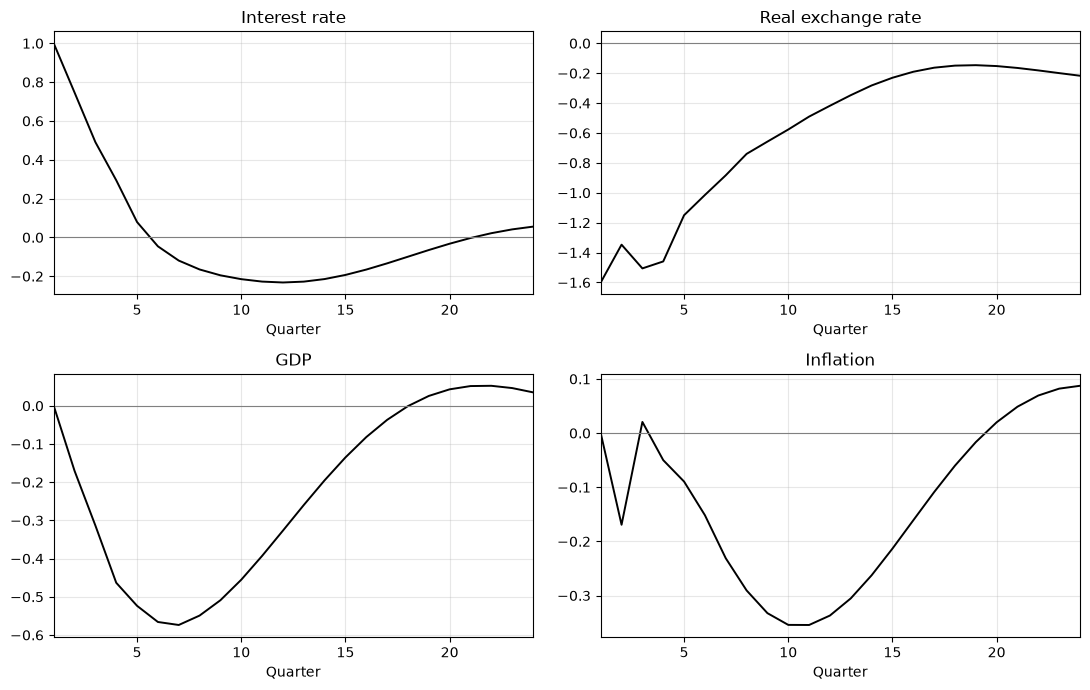

,Interest rate,Real exchange rate,GDP,Inflation
1,1.000,-1.600,-0.000,-0.000
2,0.746,-1.347,-0.170,-0.169
3,0.491,-1.506,-0.314,0.021
4,0.294,-1.459,-0.463,-0.050
5,0.079,-1.150,-0.524,-0.090
8,-0.165,-0.740,-0.549,-0.291
12,-0.232,-0.418,-0.327,-0.337
16,-0.166,-0.190,-0.082,-0.161
20,-0.032,-0.152,0.043,0.020
24,0.055,-0.217,0.035,0.087


In [26]:
irf_lr = irf_mp(A, S_lr, h)

titles = ['Interest rate', 'Real exchange rate', 'GDP', 'Inflation']
vars_ = [ir, ie, iy, ipi]

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, v, t in zip(ax.flatten(), vars_, titles):
    a.plot(hz, irf_lr[:, v], color='black', lw=1.4)
    a.axhline(0, color='grey', lw=0.8)
    a.set_title(t); a.set_xlabel('Quarter'); a.set_xlim(1, h + 1); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('q5_irf_svar.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame(irf_lr[:, vars_], columns=titles, index=hz).loc[[1, 2, 3, 4, 5, 8, 12, 16, 20, 24]].round(3)

In [27]:
fevd_lr = fevd(irf(A, S_lr, h))

tab5 = pd.DataFrame({
    'e: MP':  fevd_lr[:, ie, mp],
    'i: ER':  fevd_lr[:, ir, er],
    'i: MP':  fevd_lr[:, ir, mp],
    'e: ER':  fevd_lr[:, ie, er],
    'y: MP':  fevd_lr[:, iy, mp],
    'pi: MP': fevd_lr[:, ipi, mp],
}, index=hz)
(100 * tab5.loc[hor]).round(1)

,e: MP,i: ER,i: MP,e: ER,y: MP,pi: MP
1,24.8,23.8,62.4,71.9,0.0,0.0
4,21.1,20.4,36.9,63.9,9.0,0.5
8,20.9,13.8,24.5,60.0,17.8,2.1
12,20.6,12.4,23.8,58.7,14.5,6.1
24,19.9,11.4,21.6,56.5,9.1,6.1


## Question 6

**Bootstrap.** Residual-based recursive design: draw the centred residuals with replacement, build $y_t^*$ recursively from the estimated VAR (with the deterministic terms and the first $p$ observations as starting values), re-estimate the VAR and identify the three models. A replication is discarded if the VAR is not stable (largest eigenvalue modulus $\geq 1$) or if the identification is not valid. For the Cholesky models the identification is always valid when $\Sigma_u^*$ is positive definite. For the structural VAR the solver must find an exact solution. The bands are Efron percentile intervals.

**Delta method.** With $\theta=(\mathrm{vec}(A_1,A_2,A_3)',\mathrm{vech}(\Sigma_u)')'$, $\widehat{\mathrm{Var}}(\hat\theta)$ is block diagonal with $\Sigma_u\otimes(X'X)^{-1}$ for the lag coefficients and $\mathrm{Cov}(\hat\sigma_{ij},\hat\sigma_{kl})=(\sigma_{ik}\sigma_{jl}+\sigma_{il}\sigma_{jk})/T$ for the covariance matrix. The gradient of the impulse responses with respect to $\theta$ is computed numerically by central differences, and $\mathrm{Var}(\hat\theta_{\text{irf}})=G\,\widehat{\mathrm{Var}}(\hat\theta)\,G'$. The bands are $\hat\theta_{\text{irf}}\pm z\cdot \mathrm{se}$.

We use 68% bands (16th and 84th percentiles) as in Bjørnland.

In [28]:
level = 0.68
q_lo, q_hi = 100 * (1 - level) / 2, 100 * (1 + level) / 2
z = norm.ppf((1 + level) / 2)
models = ['Cholesky (i-exc)', 'Cholesky (exc-i)', 'Structural VAR']


def identify_all(Sigma, Alags, S_start):
    S1 = chol_identify(Sigma, [0, 1, 2, 3, 4])
    S2 = chol_identify(Sigma, [0, 1, 2, 4, 3])
    S3, valid = svar_identify(Sigma, Alags, S_start)
    return [S1, S2, S3], valid


def simulate(B, U, y, det, p, rng):
    T = y.shape[0]
    Uc = U - U.mean(axis=0)
    ystar = y.copy()
    draw = rng.integers(0, len(Uc), T - p)
    for t in range(p, T):
        xt = np.concatenate([det[t]] + [ystar[t - i] for i in range(1, p + 1)])
        ystar[t] = xt @ B + Uc[draw[t - p]]
    return ystar

In [29]:
nboot = 500
rng = np.random.default_rng(2026)

boot_irf = []      # each element: (3 models, h+1, K)
boot_fevd = []     # each element: (3 models, h+1, K, K)
n_unstable, n_invalid = 0, 0

while len(boot_irf) < nboot:
    ystar = simulate(B, U, y, det, p, rng)
    Al_b, Sig_b, _, _, _ = var_ols(ystar, p, det)
    A_b = companion(Al_b)

    if np.abs(np.linalg.eigvals(A_b)).max() >= 1:
        n_unstable += 1
        continue

    S_b, valid = identify_all(Sig_b, Al_b, S_lr)
    if not valid:
        n_invalid += 1
        continue

    boot_irf.append([irf_mp(A_b, S, h) for S in S_b])
    boot_fevd.append([fevd(irf(A_b, S, h)) for S in S_b])

boot_irf = np.array(boot_irf)
boot_fevd = np.array(boot_fevd)

print('Accepted replications:', nboot)
print('Discarded, not stable:', n_unstable)
print('Discarded, invalid identification:', n_invalid)

Accepted replications: 500
Discarded, not stable: 2
Discarded, invalid identification: 0


In [30]:
Tn = U.shape[0]
m = det.shape[1]
XtXinv = np.linalg.inv(X.T @ X)
pairs = [(i, j) for j in range(K) for i in range(j, K)]       # order of vech


def theta_from(Alags, Sigma):
    return np.concatenate([np.hstack(Alags).T.flatten(order='F'), [Sigma[i, j] for i, j in pairs]])


def unpack(theta):
    Blag = theta[:K * K * p].reshape(K * p, K, order='F')
    Alags = [Blag[(i - 1) * K:i * K].T for i in range(1, p + 1)]
    Sigma = np.zeros((K, K))
    for v, (i, j) in zip(theta[K * K * p:], pairs):
        Sigma[i, j] = Sigma[j, i] = v
    return Alags, Sigma


cov_A = np.kron(Sigma, XtXinv[m:, m:])
cov_S = np.array([[(Sigma[i, k] * Sigma[j, l] + Sigma[i, l] * Sigma[j, k]) / Tn for (k, l) in pairs] for (i, j) in pairs])
cov_theta = np.block([[cov_A, np.zeros((len(cov_A), len(cov_S)))], [np.zeros((len(cov_S), len(cov_A))), cov_S]])
theta_hat = theta_from(Alags, Sigma)


def delta_se(stat):
    f0 = stat(theta_hat)
    G = np.zeros((f0.size, theta_hat.size))
    for k in range(theta_hat.size):
        step = 1e-6 * max(abs(theta_hat[k]), 1e-3)
        tp, tm = theta_hat.copy(), theta_hat.copy()
        tp[k] += step
        tm[k] -= step
        G[:, k] = (stat(tp) - stat(tm)).flatten() / (2 * step)
    return np.sqrt(np.diag(G @ cov_theta @ G.T)).reshape(f0.shape)


def stat_irf(theta):
    Al, Sg = unpack(theta)
    S_all, _ = identify_all(Sg, Al, S_lr)
    return np.array([irf_mp(companion(Al), S, h) for S in S_all])


irf_hat = stat_irf(theta_hat)          # (3 models, h+1, K)
se_irf = delta_se(stat_irf)

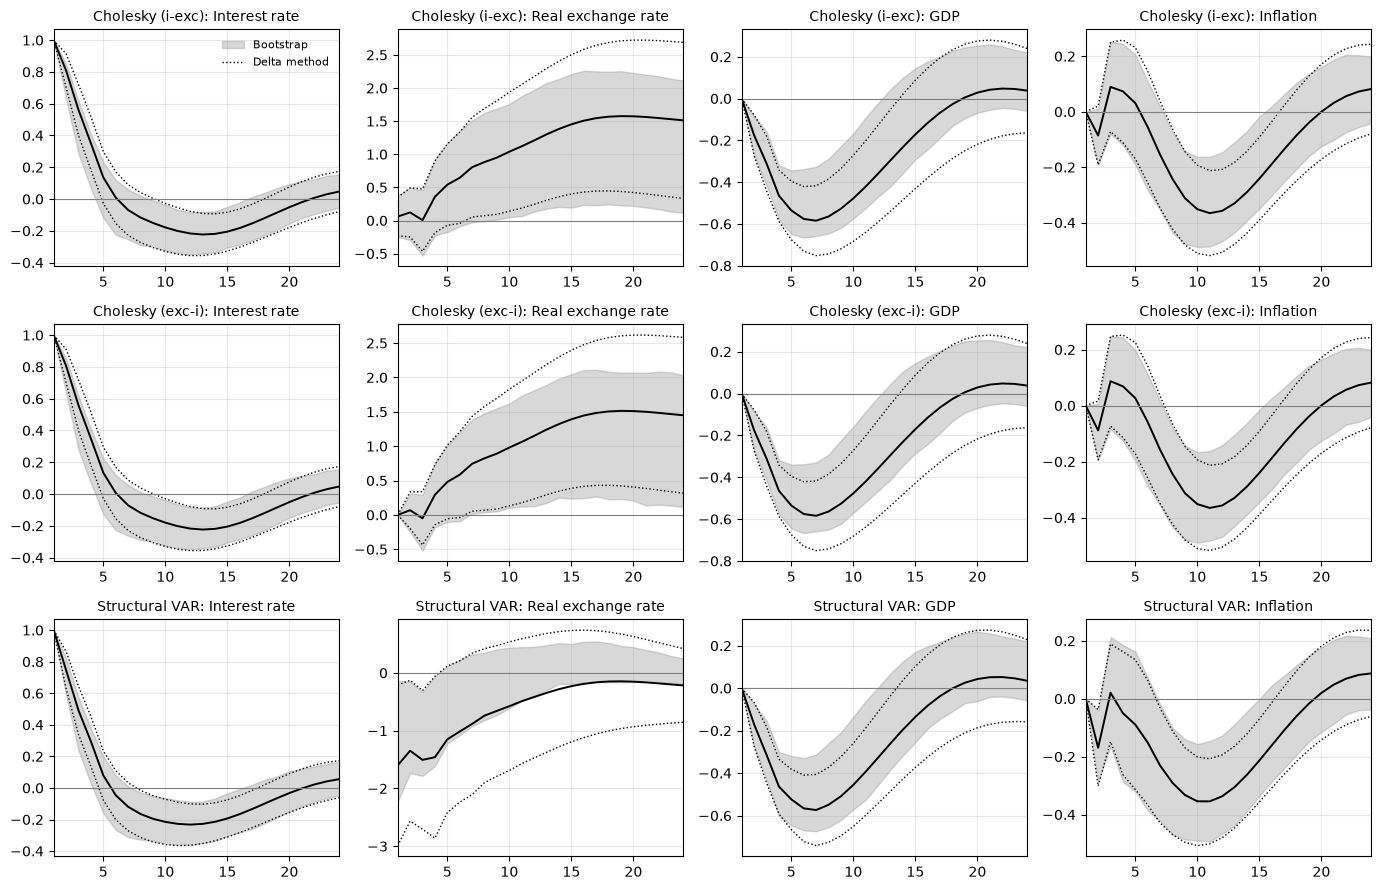

In [31]:
lo_b, hi_b = np.percentile(boot_irf, [q_lo, q_hi], axis=0)

fig, ax = plt.subplots(3, 4, figsize=(14, 9))
for mi, mod in enumerate(models):
    for j, (v, t) in enumerate(zip(vars_, titles)):
        a = ax[mi, j]
        a.fill_between(hz, lo_b[mi, :, v], hi_b[mi, :, v], color='grey', alpha=0.3, label='Bootstrap')
        a.plot(hz, irf_hat[mi, :, v] - z * se_irf[mi, :, v], ':', color='black', lw=1, label='Delta method')
        a.plot(hz, irf_hat[mi, :, v] + z * se_irf[mi, :, v], ':', color='black', lw=1)
        a.plot(hz, irf_hat[mi, :, v], color='black', lw=1.4)
        a.axhline(0, color='grey', lw=0.8)
        a.set_xlim(1, h + 1); a.grid(alpha=0.3)
        a.set_title(f'{mod}: {t}', fontsize=10)
ax[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig('q6_irf_bands.png', dpi=200, bbox_inches='tight')
plt.show()

## Question 7

Efron percentile intervals for the FEVD from the bootstrap in Question 6. We report the contributions of monetary policy and exchange rate shocks to the interest rate and the real exchange rate (in first differences). The standard errors are the standard deviations of the bootstrap draws.

In [32]:
fevd_hat = np.array([fevd(irf(A, S, h)) for S in [S_45, S_54, S_lr]])      # (3, h+1, K, K)
cases = [(ir, mp, 'i: MP'), (ir, er, 'i: ER'), (ie, mp, 'e: MP'), (ie, er, 'e: ER')]

lo_f, hi_f = np.percentile(boot_fevd, [q_lo, q_hi], axis=0)
se_f_boot = boot_fevd.std(axis=0)

rows = []
for mi, mod in enumerate(models):
    for (v, s, lab) in cases:
        for hh in hor:
            rows.append([mod, lab, hh, fevd_hat[mi, hh - 1, v, s], se_f_boot[mi, hh - 1, v, s],
                         lo_f[mi, hh - 1, v, s], hi_f[mi, hh - 1, v, s]])
tab7 = pd.DataFrame(rows, columns=['Model', 'FEVD', 'Horizon', 'Estimate', 'SE (bootstrap)', 'Lower', 'Upper'])
tab7.iloc[:, 3:] = 100 * tab7.iloc[:, 3:]
tab7.round(1)

,Model,FEVD,Horizon,Estimate,SE (bootstrap),Lower,Upper
0,Cholesky (i-exc),i: MP,1,86.2,8.9,73.6,90.9
1,Cholesky (i-exc),i: MP,4,56.5,11.5,41.2,66.2
2,Cholesky (i-exc),i: MP,8,37.2,11.0,27.0,51.0
3,Cholesky (i-exc),i: MP,12,35.2,10.7,25.2,47.8
4,Cholesky (i-exc),i: MP,24,32.0,11.1,21.5,44.4
5,Cholesky (i-exc),i: ER,1,0.0,0.0,0.0,0.0
6,Cholesky (i-exc),i: ER,4,0.8,2.7,0.4,4.6
7,Cholesky (i-exc),i: ER,8,1.1,3.5,0.7,5.9
8,Cholesky (i-exc),i: ER,12,1.1,3.7,0.8,6.6
9,Cholesky (i-exc),i: ER,24,1.0,3.6,0.9,6.7


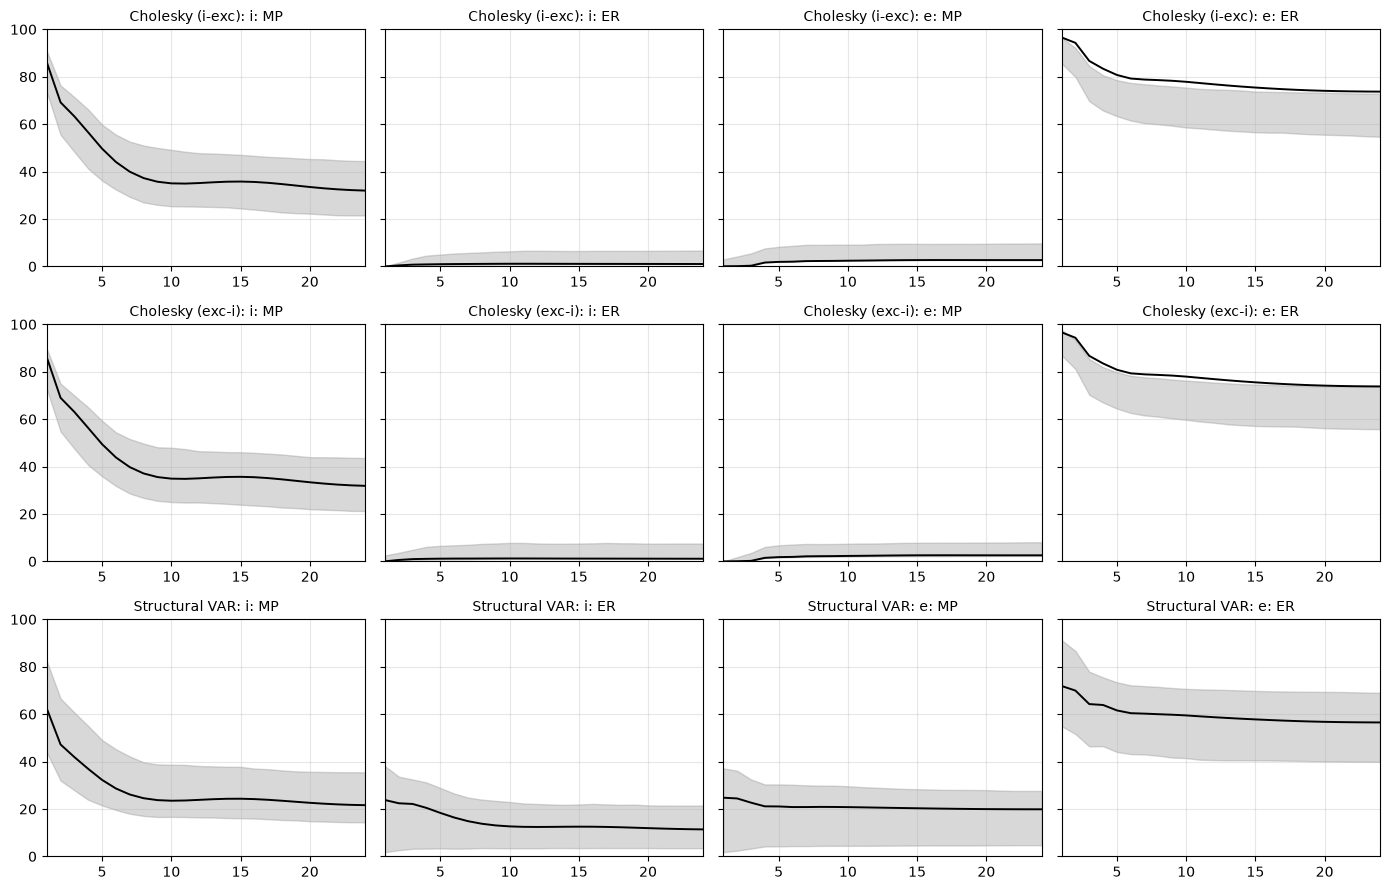

In [33]:
fig, ax = plt.subplots(3, 4, figsize=(14, 9), sharey=True)
for mi, mod in enumerate(models):
    for j, (v, s, lab) in enumerate(cases):
        a = ax[mi, j]
        a.fill_between(hz, 100 * lo_f[mi, :, v, s], 100 * hi_f[mi, :, v, s], color='grey', alpha=0.3)
        a.plot(hz, 100 * fevd_hat[mi, :, v, s], color='black', lw=1.4)
        a.set_xlim(1, h + 1); a.set_ylim(0, 100); a.grid(alpha=0.3)
        a.set_title(f'{mod}: {lab}', fontsize=10)
plt.tight_layout()
plt.savefig('q7_fevd_efron.png', dpi=200, bbox_inches='tight')
plt.show()

## Question 8

Delta-method standard errors for the FEVD, computed as in Question 6 with the FEVD as the function of $\theta$. The bands are $\hat\omega\pm z\cdot\mathrm{se}$.

In [34]:
def stat_fevd(theta):
    Al, Sg = unpack(theta)
    S_all, _ = identify_all(Sg, Al, S_lr)
    return np.array([fevd(irf(companion(Al), S, h)) for S in S_all])


se_f_delta = delta_se(stat_fevd)

tab8 = tab7[['Model', 'FEVD', 'Horizon', 'Estimate', 'SE (bootstrap)']].copy()
se_d, lo_d, hi_d = [], [], []
for mi, mod in enumerate(models):
    for (v, s, lab) in cases:
        for hh in hor:
            est, se = fevd_hat[mi, hh - 1, v, s], se_f_delta[mi, hh - 1, v, s]
            se_d.append(se); lo_d.append(est - z * se); hi_d.append(est + z * se)
tab8['SE (delta)'] = 100 * np.array(se_d)
tab8['Lower (delta)'] = 100 * np.array(lo_d)
tab8['Upper (delta)'] = 100 * np.array(hi_d)
tab8['Lower (Efron)'] = tab7['Lower']
tab8['Upper (Efron)'] = tab7['Upper']
tab8.round(1)

,Model,FEVD,Horizon,Estimate,SE (bootstrap),SE (delta),Lower (delta),Upper (delta),Lower (Efron),Upper (Efron)
0,Cholesky (i-exc),i: MP,1,86.2,8.9,6.9,79.3,93.1,73.6,90.9
1,Cholesky (i-exc),i: MP,4,56.5,11.5,11.8,44.8,68.2,41.2,66.2
2,Cholesky (i-exc),i: MP,8,37.2,11.0,12.5,24.8,49.6,27.0,51.0
3,Cholesky (i-exc),i: MP,12,35.2,10.7,12.6,22.6,47.7,25.2,47.8
4,Cholesky (i-exc),i: MP,24,32.0,11.1,12.9,19.1,44.8,21.5,44.4
5,Cholesky (i-exc),i: ER,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,Cholesky (i-exc),i: ER,4,0.8,2.7,1.8,-0.9,2.6,0.4,4.6
7,Cholesky (i-exc),i: ER,8,1.1,3.5,2.5,-1.4,3.5,0.7,5.9
8,Cholesky (i-exc),i: ER,12,1.1,3.7,2.7,-1.5,3.8,0.8,6.6
9,Cholesky (i-exc),i: ER,24,1.0,3.6,2.5,-1.5,3.5,0.9,6.7


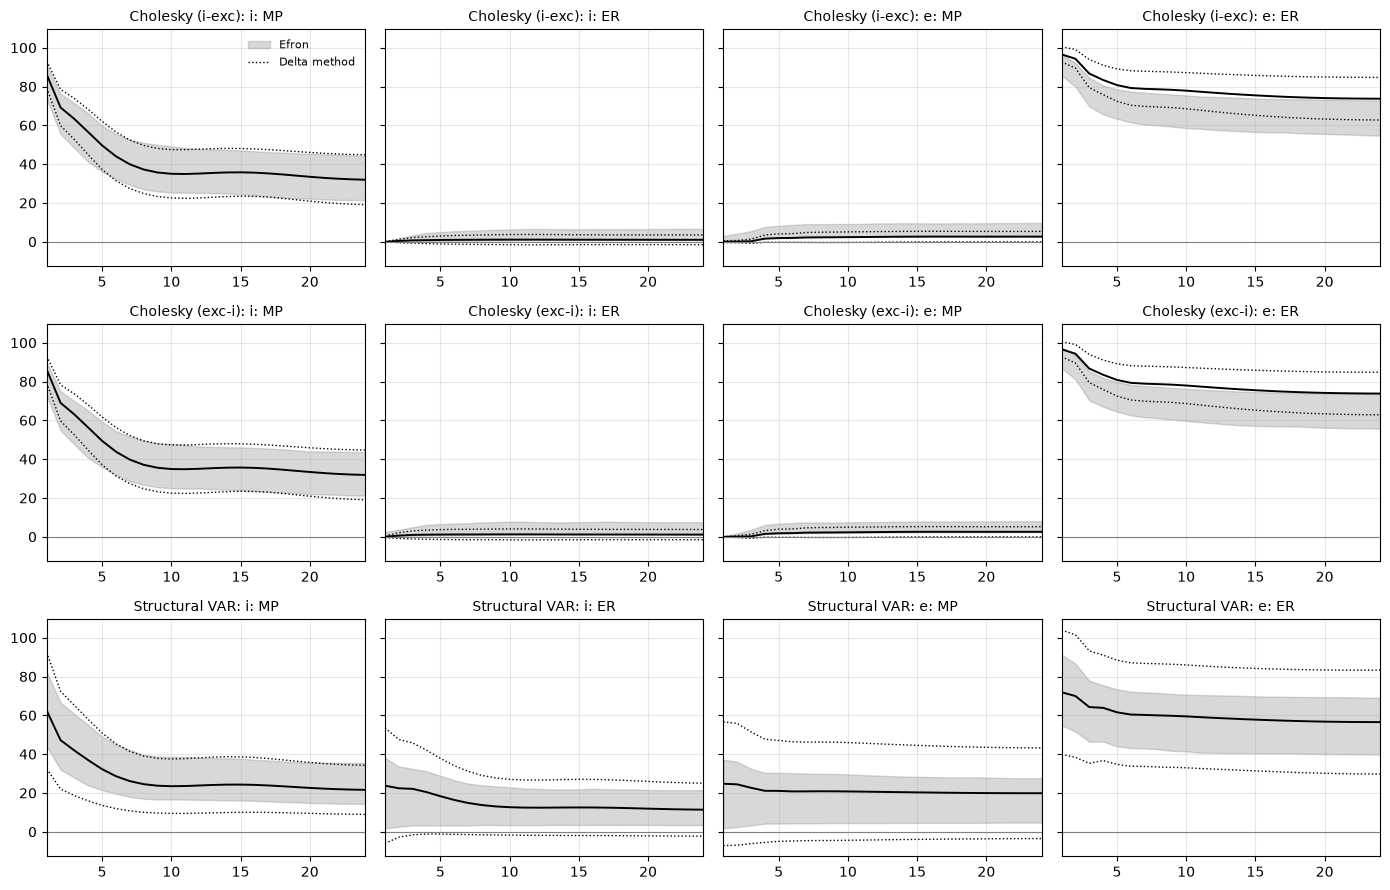

In [35]:
fig, ax = plt.subplots(3, 4, figsize=(14, 9), sharey=True)
for mi, mod in enumerate(models):
    for j, (v, s, lab) in enumerate(cases):
        a = ax[mi, j]
        est = 100 * fevd_hat[mi, :, v, s]
        se = 100 * se_f_delta[mi, :, v, s]
        a.fill_between(hz, 100 * lo_f[mi, :, v, s], 100 * hi_f[mi, :, v, s], color='grey', alpha=0.3, label='Efron')
        a.plot(hz, est - z * se, ':', color='black', lw=1, label='Delta method')
        a.plot(hz, est + z * se, ':', color='black', lw=1)
        a.plot(hz, est, color='black', lw=1.4)
        a.axhline(0, color='grey', lw=0.8)
        a.set_xlim(1, h + 1); a.grid(alpha=0.3)
        a.set_title(f'{mod}: {lab}', fontsize=10)
ax[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig('q8_fevd_efron_delta.png', dpi=200, bbox_inches='tight')
plt.show()